In [173]:
import requests
import time
from bs4 import BeautifulSoup as bs
import pandas as pd
import numpy as np
import seaborn as sb
import matplotlib.pyplot as plt
import re
HEADERS = {"User-Agent": "WEBDATASCIENCE OSRS Research Project/1.0, simon.spillane@colorado.edu"}


In [153]:
geHTML = requests.get("https://oldschool.runescape.wiki/w/Grand_Exchange#Items_regulated_via_item_sink").text



str

In [86]:
sinkSoup = bs(geHTML)


In [80]:
SinkListResults = {}

for th in sinkSoup.find_all('th'):
    if th.get_text(strip=True) == 'Item Sink List':
        row = th.find_parent('tr')
        for sib in row.find_next_siblings('tr'):
            if sib.find('th'):          # next section heading, stop
                break
            for li in sib.select('td > ul > li'):
                a = li.find('a', title=True)           # e.g. Chambers of Xeric
                if not a:
                    continue
                # text that belongs to this <li> only, not the nested <ul>
                label = ''.join(li.find_all(string=True, recursive=False)).strip()
                items = [x['title'] for x in li.select('ul a[title]')]
                SinkListResults[a['title']] = {'label': label, 'items': items}
        break
SinkListResults

{'Chambers of Xeric': {'label': 'uniques',
  'items': ['Chambers of Xeric',
   'Ancestral hat',
   'Ancestral robe top',
   'Ancestral robe bottom',
   "Dinh's bulwark",
   'Elder maul',
   'Kodai wand',
   'Prayer scroll',
   'Arcane prayer scroll',
   'Dexterous prayer scroll',
   'Twisted buckler',
   'Twisted bow']},
 'Theatre of Blood': {'label': 'uniques',
  'items': ['Theatre of Blood',
   'Avernic defender hilt',
   'Sanguinesti staff',
   'Scythe of Vitur']},
 'Tombs of Amascut': {'label': 'uniques',
  'items': ['Tombs of Amascut',
   "Elidinis' ward",
   'Lightbearer',
   'Masori mask (f)',
   'Masori body (f)',
   'Masori chaps (f)',
   "Osmumten's fang",
   "Tumeken's shadow"]},
 'Dagannoth Kings': {'label': 'uniques',
  'items': ['Dagannoth Kings', 'Archers ring', 'Berserker ring']},
 'God Wars Dungeon': {'label': 'uniques',
  'items': ['God Wars Dungeon',
   'Armadyl armour',
   'Bandos armour',
   'Bandos boots',
   'Godsword',
   'Ancient godsword',
   'Armadyl godsword

In [159]:
sinkitemsDF = pd.DataFrame(SinkListResults)

sinkList = []
itemc = 0

exceptions = [
    "Chambers of Xeric", "Theatre of Blood", "Tombs of Amascut",
    "God Wars Dungeon", "Dagannoth Kings", "Godsword",
    "Nightmare", "Slayer", "Zenyte shard","Prayer scroll",
]

def is_excepted(item):
    name = str(item).lower()
    return any(ex.lower() in name for ex in exceptions)

for itemc in range(sinkitemsDF.shape[1]):
    for item in sinkitemsDF.iloc[:, itemc]['items']:
        if is_excepted(item):
            continue
        sinkList.append(item)
len(sinkList)

52

In [161]:

URL = "https://api.weirdgloop.org/exchange/history/osrs/latest"

PIECES = ["chestplate", "chainskirt", "helmet", "tassets",
          "great helm", "hauberk", "plateskirt"]
SUFFIX = " (uncharged)"

def fetch_item_ids(names, chunk_size=50, min_interval=1.0, max_requests=20,
                   max_retries=3, retry_fixes=True):
    names = pd.Series(names).dropna().astype(str).str.strip()
    names = names[names != ""].drop_duplicates().tolist()

    ids, missing = {}, []
    requests_made = 0
    last_request = 0.0

    for i in range(0, len(names), chunk_size):
        chunk = names[i:i + chunk_size]

        if requests_made >= max_requests:
            print(f"Request cap ({max_requests}) reached; skipping remaining names.")
            missing.extend(names[i:])
            break

        data = None
        for attempt in range(max_retries):
            wait = min_interval - (time.monotonic() - last_request)
            if wait > 0:
                time.sleep(wait)

            r = requests.get(URL, params={"name": "|".join(chunk)},
                             headers=HEADERS, timeout=30)
            last_request = time.monotonic()
            requests_made += 1

            if r.status_code == 429 or r.status_code >= 500:
                time.sleep(float(r.headers.get("Retry-After", 2 ** attempt)))
                if requests_made >= max_requests:
                    break
                continue

            if r.status_code in (400, 404):
                data = {}
                break

            r.raise_for_status()
            data = r.json()
            break

        if not data or data.get("success") is False:
            missing.extend(chunk)
            continue

        found = {k.lower(): v["id"] for k, v in data.items()}
        for n in chunk:
            if n.lower() in found:
                ids[n] = int(found[n.lower()])
            else:
                missing.append(n)

    print(f"{requests_made} requests, {len(ids)} found, {len(missing)} missing")

    # Second pass: try fixed names ONCE, with retry_fixes=False so it can't recurse
    if retry_fixes and missing:
        fixed_missing = []
        for item in missing:
            if re.search(r"armour", item, flags=re.IGNORECASE):
                for piece in PIECES:
                    fixed_missing.append(re.sub(r"armour", piece, item, flags=re.IGNORECASE))
            fixed_missing.append(item + SUFFIX)

        ids2, still_missing = fetch_item_ids(fixed_missing, max_requests=5,
                                             retry_fixes=False)
        ids.update(ids2)

        # Only report the originals as missing if none of their variants were found
        generated = set(fixed_missing)
        missing = [n for n in missing if n not in ids]
        print(f"After fixes: {len(ids)} found")

    return ids, missing

ids, missing = fetch_item_ids(sinkList)


2 requests, 44 found, 8 missing
1 requests, 13 found, 16 missing
After fixes: 57 found


In [167]:
ItemIdDF = pd.DataFrame({"item": list(ids), "id": list(ids.values())})
ItemIdDF

,item,id
0,Ancestral hat,21018
1,Ancestral robe top,21021
2,Ancestral robe bottom,21024
3,Dinh's bulwark,21015
4,Elder maul,21003
5,Kodai wand,21006
6,Twisted buckler,21000
7,Twisted bow,20997
8,Avernic defender hilt,22477
9,Elidinis' ward,25985


In [178]:
import time
import requests
import pandas as pd

GLOOP_ALL_URL = "https://api.weirdgloop.org/exchange/history/osrs/all"

def fetch_price_history(item_df, chunk_size=10, min_interval=1.0,
                        max_requests=30, start_date="2026-08-20", end_date="2026-12-20"):
    """
    item_df    : DataFrame with an 'id' column (and optionally 'item')
    chunk_size : item ids per request (kept small since /all responses are large)
    Returns (history_df, failed_ids), where history_df has one row per
    item per timestamp: id, item, timestamp, price, volume, date.
    """
    ids = (item_df["id"].dropna().astype(int).drop_duplicates().tolist())
    id_to_name = {}
    if "item" in item_df.columns:
        id_to_name = (item_df.dropna(subset=["id"])
                             .assign(id=lambda d: d["id"].astype(int))
                             .drop_duplicates("id")
                             .set_index("id")["item"].to_dict())

    frames, failed = [], []
    requests_made, last_request = 0, 0.0

    for i in range(0, len(ids), chunk_size):
        chunk = ids[i:i + chunk_size]

        if requests_made >= max_requests:
            print(f"Request cap ({max_requests}) reached; skipping remaining ids.")
            failed.extend(ids[i:])
            break

        wait = min_interval - (time.monotonic() - last_request)
        if wait > 0:
            time.sleep(wait)

        try:
            r = requests.get(GLOOP_ALL_URL,
                             params={"id": "|".join(map(str, chunk))},
                             headers=HEADERS, timeout=60)
            last_request = time.monotonic()
            requests_made += 1
            r.raise_for_status()
            data = r.json()
        except (requests.RequestException, ValueError) as e:
            print(f"Chunk starting at index {i} failed: {e}")
            failed.extend(chunk)
            continue


In [211]:
def fetch_price_history(item_df, endpoint="all", chunk_size=1, min_interval=1.0,
                        max_requests=1000, start_date=None, end_date=None):
    url = f"https://api.weirdgloop.org/exchange/history/osrs/{endpoint}"

    ids = item_df["id"].dropna().astype(int).drop_duplicates().tolist()
    id_to_name = {}
    if "item" in item_df.columns:
        id_to_name = (item_df.dropna(subset=["id"])
                             .assign(id=lambda d: d["id"].astype(int))
                             .drop_duplicates("id")
                             .set_index("id")["item"].to_dict())

    frames, failed = [], []
    requests_made, last_request = 0, 0.0

    for i in range(0, len(ids), chunk_size):
        chunk = ids[i:i + chunk_size]

        if requests_made >= max_requests:
            print(f"Request cap ({max_requests}) reached; skipping remaining ids.")
            failed.extend(ids[i:])
            break

        wait = min_interval - (time.monotonic() - last_request)
        if wait > 0:
            time.sleep(wait)

        try:
            r = requests.get(url,
                             params={"id": "|".join(map(str, chunk))},
                             headers=HEADERS, timeout=60)
            last_request = time.monotonic()
            requests_made += 1
            r.raise_for_status()
            data = r.json()
        except (requests.RequestException, ValueError) as e:
            print(f"Chunk starting at index {i} failed: {e}")
            failed.extend(chunk)
            continue

        if data.get("success") is False:
            print(f"API error for chunk at index {i}: {data.get('error', data)}")
            failed.extend(chunk)
            continue

        got = set()
        for key, records in data.items():
            if not str(key).isdigit() or not isinstance(records, list) or not records:
                continue
            f = pd.DataFrame(records)
            f["id"] = int(key)
            frames.append(f)
            got.add(int(key))

        failed.extend(x for x in chunk if x not in got)

    cols = ["id", "item", "timestamp", "price", "volume", "date"]
    if not frames:
        print(f"{requests_made} requests, nothing returned, {len(failed)} failed")
        return pd.DataFrame(columns=cols), failed

    history = pd.concat(frames, ignore_index=True)
    history["date"] = pd.to_datetime(history["timestamp"], unit="ms")
    history["item"] = history["id"].map(id_to_name)

    if start_date is not None:
        history = history[history["date"] >= start_date]
    if end_date is not None:
        history = history[history["date"] < end_date]

    history = history[[c for c in cols if c in history.columns]]
    print(f"{requests_made} requests, {history['id'].nunique()} items, "
          f"{len(history)} rows, {len(failed)} failed")
    return history.reset_index(drop=True), failed

In [212]:
history, failed = fetch_price_history(ItemIdDF, endpoint="all", min_interval=1.0)
history.to_csv("sink_history_all.csv", index=False)

57 requests, 57 items, 196810 rows, 0 failed


In [218]:
sinkHistDF = pd.read_csv('sink_history_all.csv')
sinkHistDF

,id,item,timestamp,price,volume,date
0,21018,Ancestral hat,1483660800000,18124763,NaN,2017-01-06 00:00:00
1,21018,Ancestral hat,1483747200000,18907171,NaN,2017-01-07 00:00:00
2,21018,Ancestral hat,1483833600000,19736647,NaN,2017-01-08 00:00:00
3,21018,Ancestral hat,1483920000000,20614331,NaN,2017-01-09 00:00:00
4,21018,Ancestral hat,1484006400000,21566839,NaN,2017-01-10 00:00:00
...,...,...,...,...,...,...
196805,24421,Inquisitor's plateskirt,1794170518000,141432059,38.0,2026-11-08 20:41:58
196806,24421,Inquisitor's plateskirt,1794180177000,145366869,33.0,2026-11-08 23:22:57
196807,24421,Inquisitor's plateskirt,1794189173000,145366869,41.0,2026-11-09 01:52:53
196808,24421,Inquisitor's plateskirt,1794201036000,144828852,44.0,2026-11-09 05:10:36


In [221]:
sinkHistDF.kys()

Index(['id', 'item', 'timestamp', 'price', 'volume', 'date'], dtype='str')

In [238]:
unique_items = sinkHistDF["item"].unique()
len(unique_items)

57

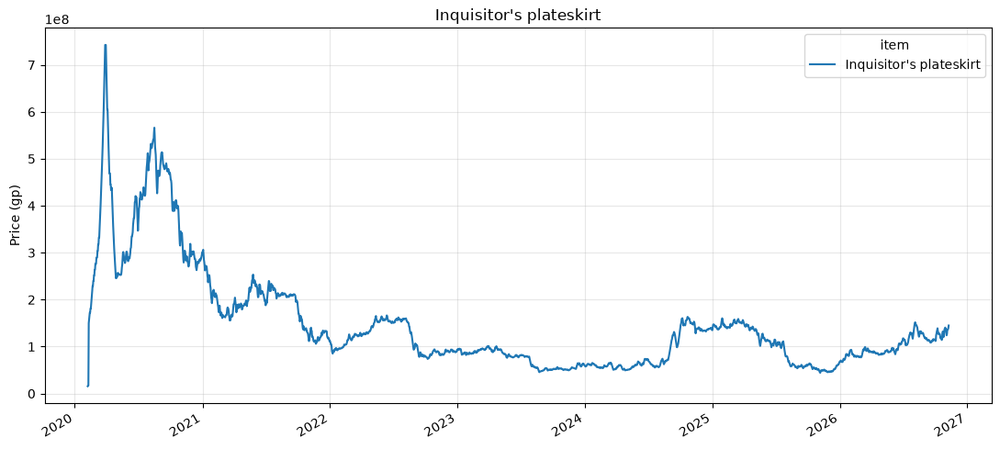

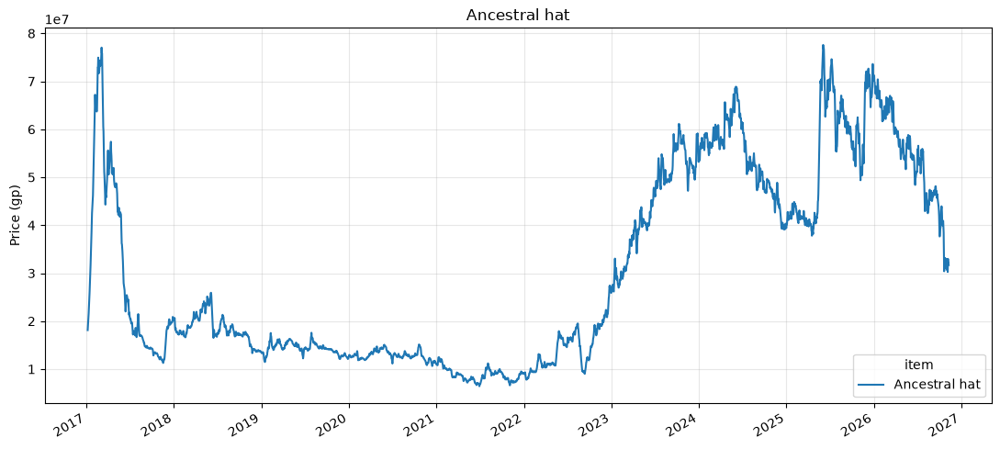

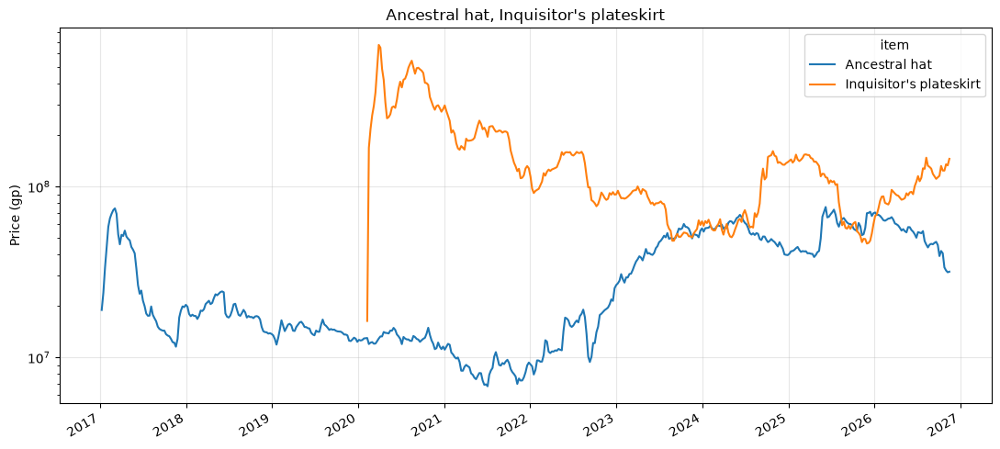

In [223]:
sinkHistDF["date"] = pd.to_datetime(sinkHistDF["date"])

def plot_items(df, items, freq="D", title=None, log=False):
    """Plot price over time for one or more items.
    freq: 'D' daily, 'W' weekly, 'M' monthly
    """
    if isinstance(items, str):
        items = [items]

    sub = df[df["item"].isin(items)]

    prices = (
        sub.groupby(["item", pd.Grouper(key="date", freq=freq)])["price"]
        .mean()
        .unstack("item")
    )

    ax = prices.plot(figsize=(11, 5), title=title or ", ".join(items), logy=log)
    ax.set_ylabel("Price (gp)")
    ax.set_xlabel("")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

plot_items(sinkHistDF, "Inquisitor's plateskirt")
plot_items(sinkHistDF, "Ancestral hat")
plot_items(sinkHistDF, ["Ancestral hat", "Inquisitor's plateskirt"], freq="W", log=True)

In [225]:
def plot_items_price(df, items, freq="D", title=None, log=False, vline="2021-12-09"):
    if isinstance(items, str):
        items = [items]

    sub = df[df["item"].isin(items)]

    prices = (
        sub.groupby(["item", pd.Grouper(key="date", freq=freq)])["price"]
        .mean()
        .unstack("item")
    )

    ax = prices.plot(figsize=(11, 5), title=title or ", ".join(items), logy=log)
    if vline:
        ax.axvline(pd.to_datetime(vline), color="red", linestyle="--", label=vline)
        ax.legend()
    ax.set_ylabel("Price (gp)")
    ax.set_xlabel("")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

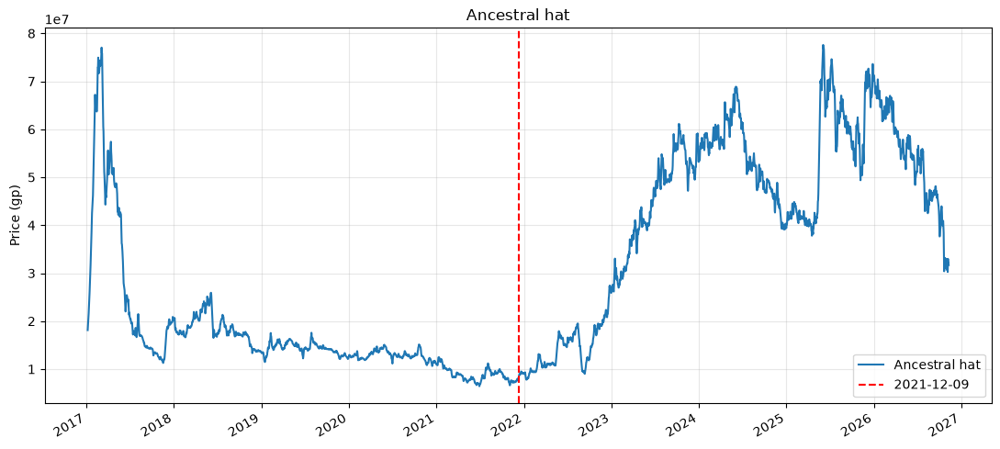

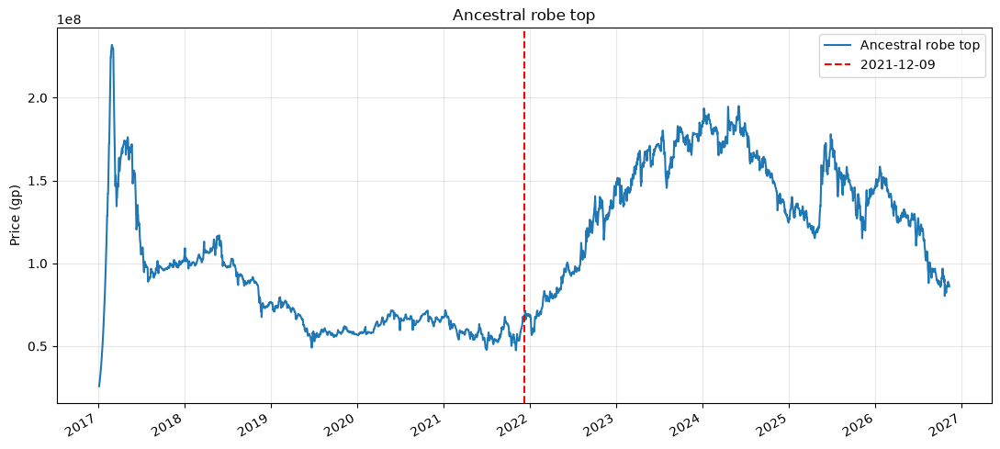

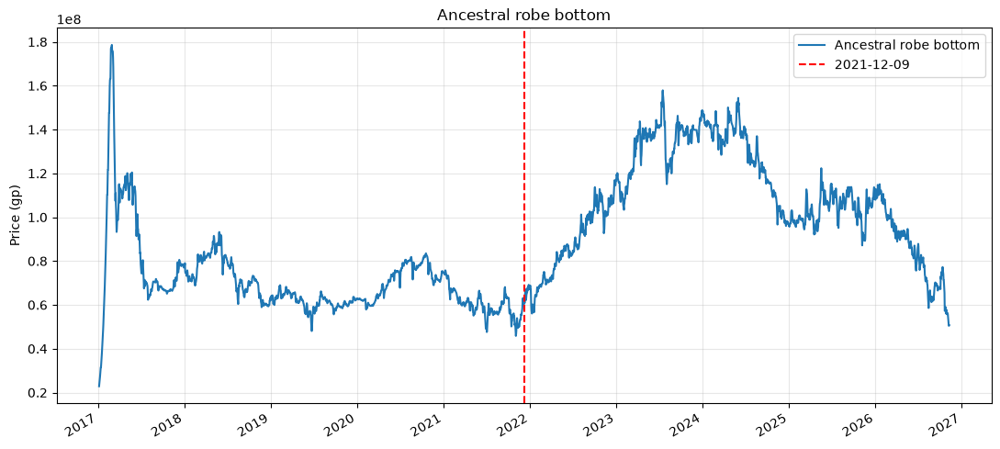

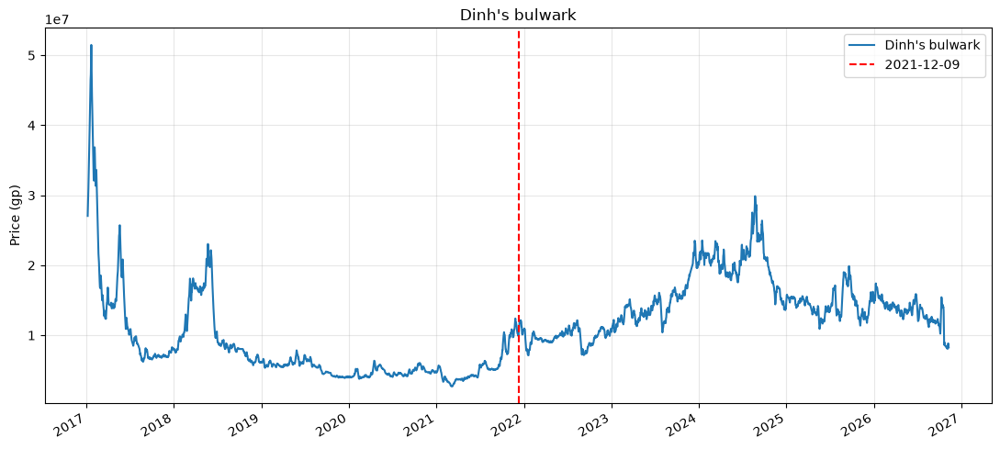

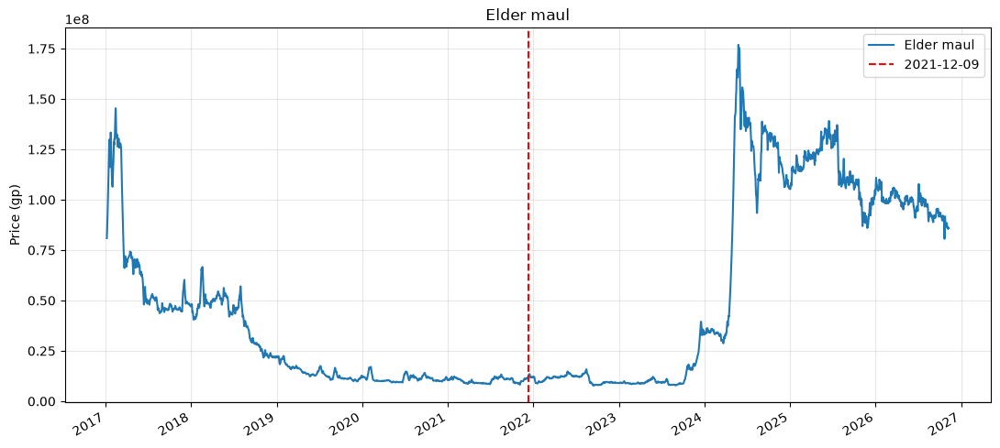

...

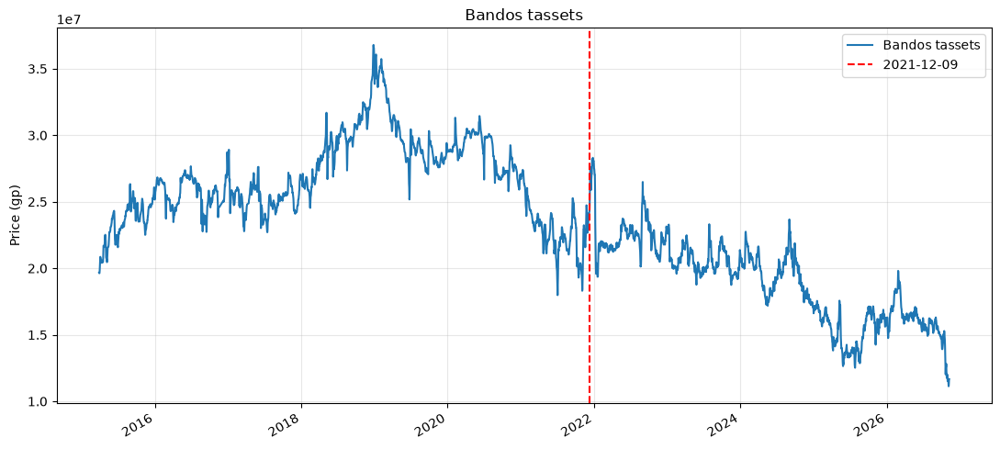

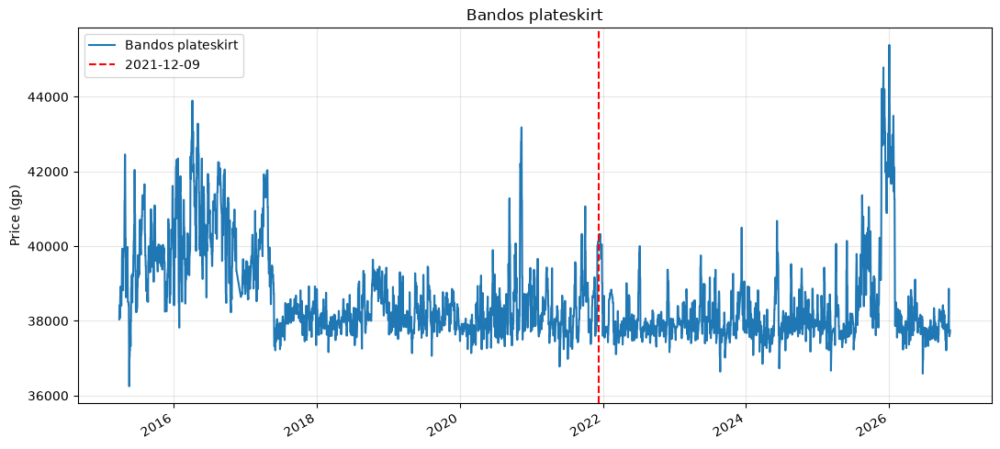

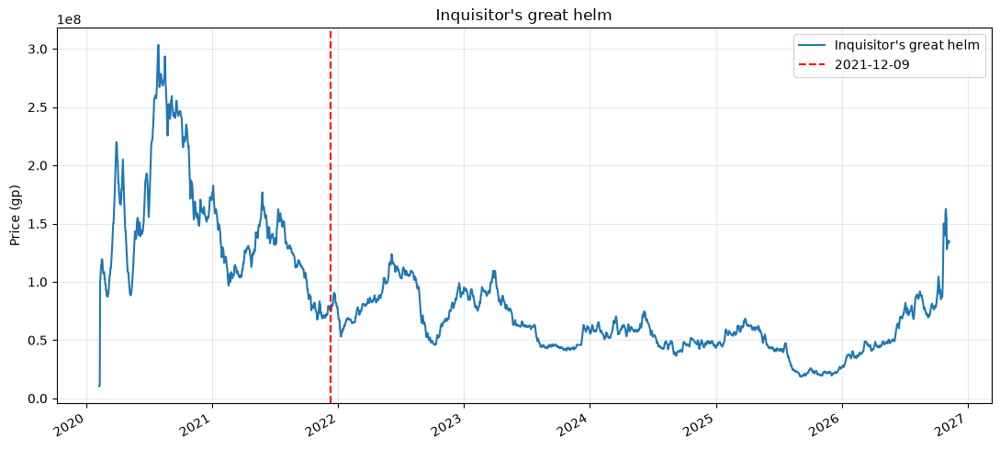

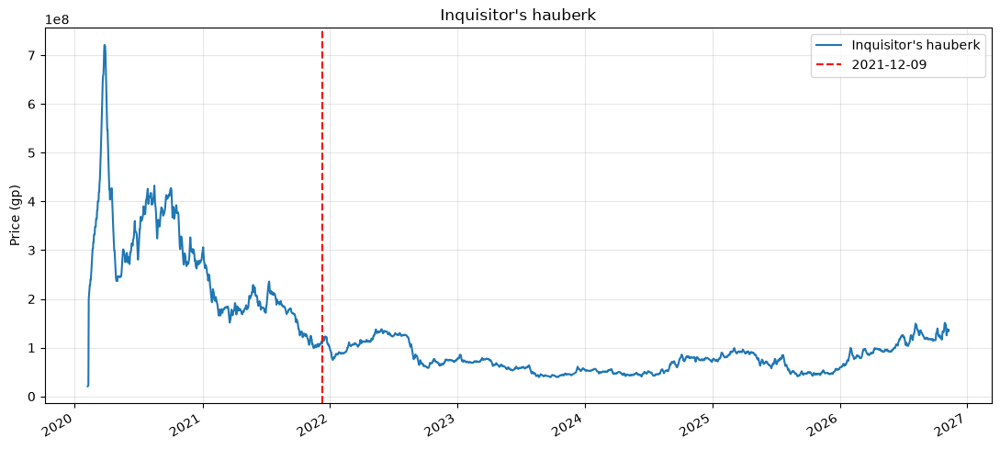

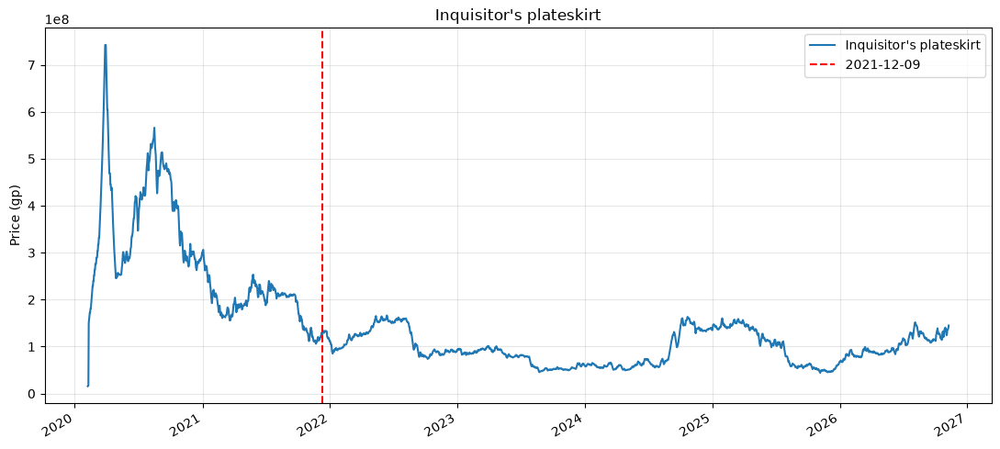

In [227]:


for item in unique_items:
    plot_items_price(sinkHistDF, item)


In [228]:
def plot_items_volume(df, items, freq="D", title=None, log=False, vline="2021-12-09"):
    if isinstance(items, str):
        items = [items]

    sub = df[df["item"].isin(items)]

    volumes = (
        sub.groupby(["item", pd.Grouper(key="date", freq=freq)])["volume"]
        .mean()
        .unstack("item")
    )

    ax = volumes.plot(figsize=(11, 5), title=title or ", ".join(items), logy=log)
    if vline:
        ax.axvline(pd.to_datetime(vline), color="red", linestyle="--", label=vline)
        ax.legend()
    ax.set_ylabel("Volume")
    ax.set_xlabel("")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

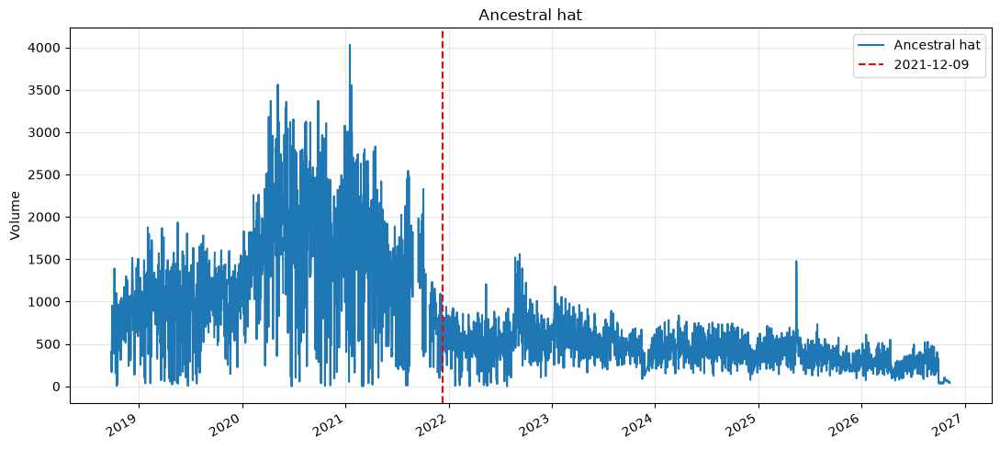

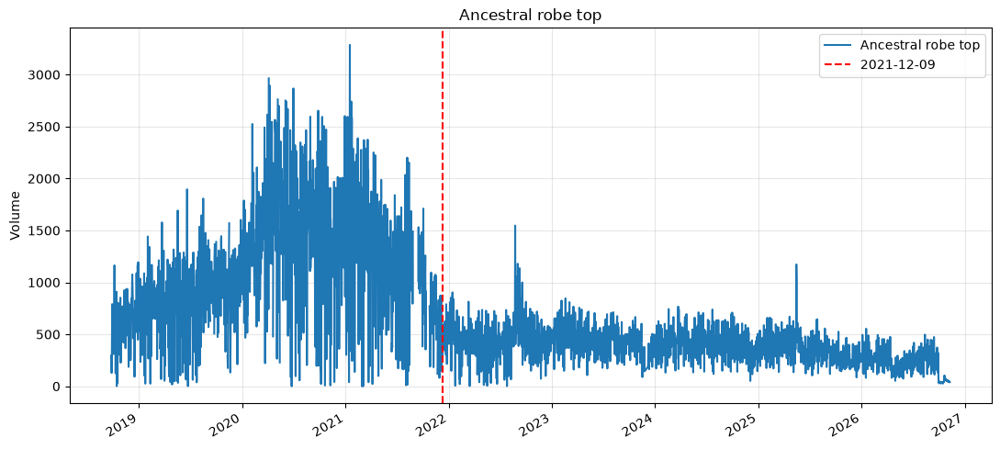

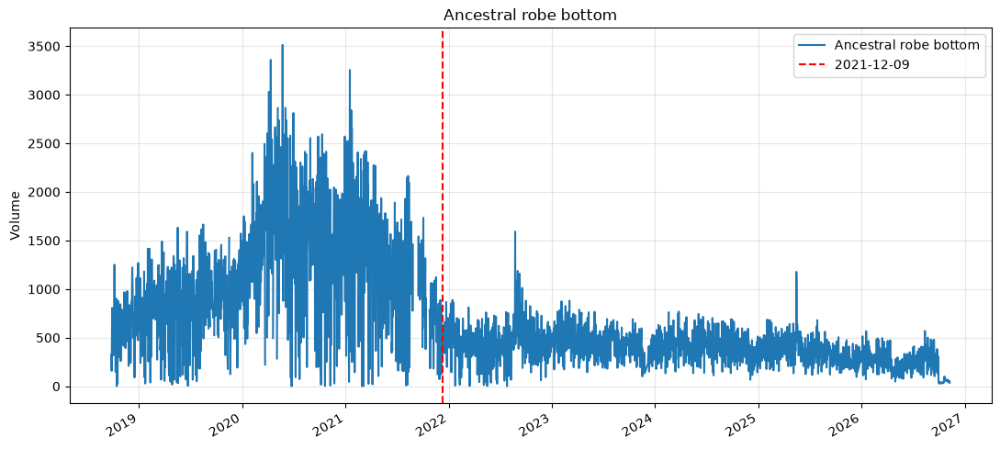

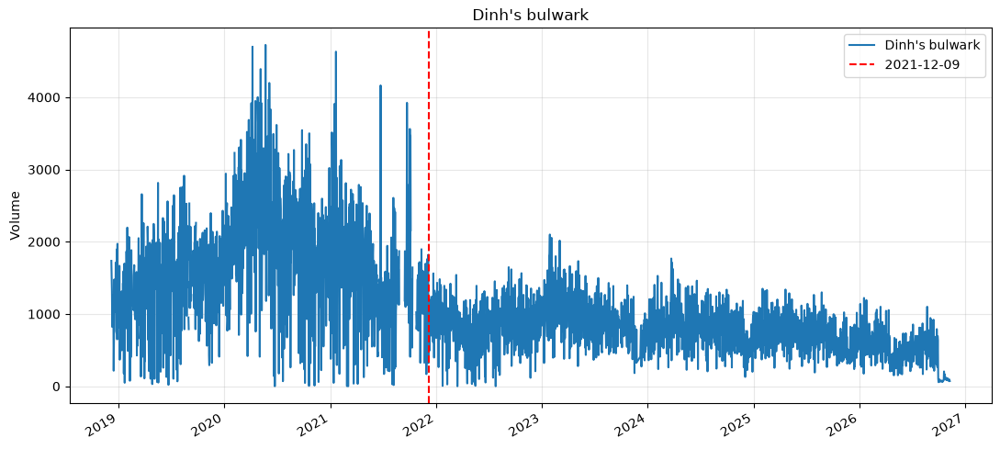

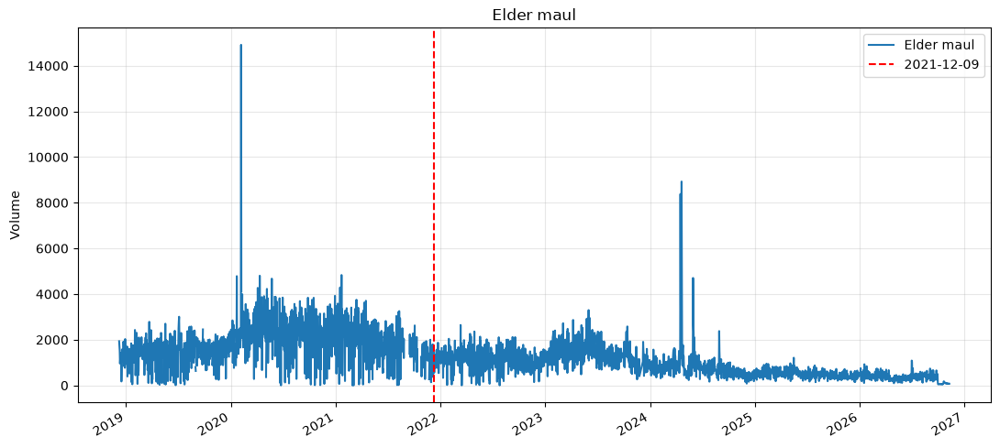

...

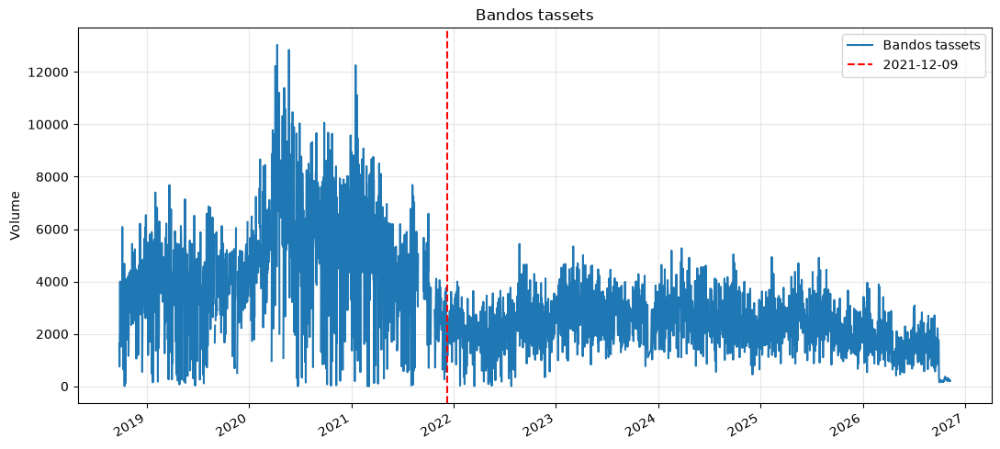

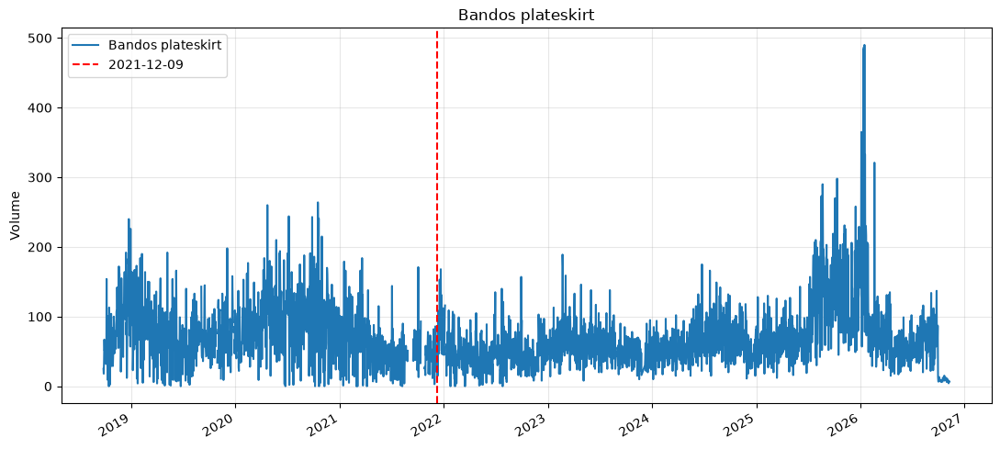

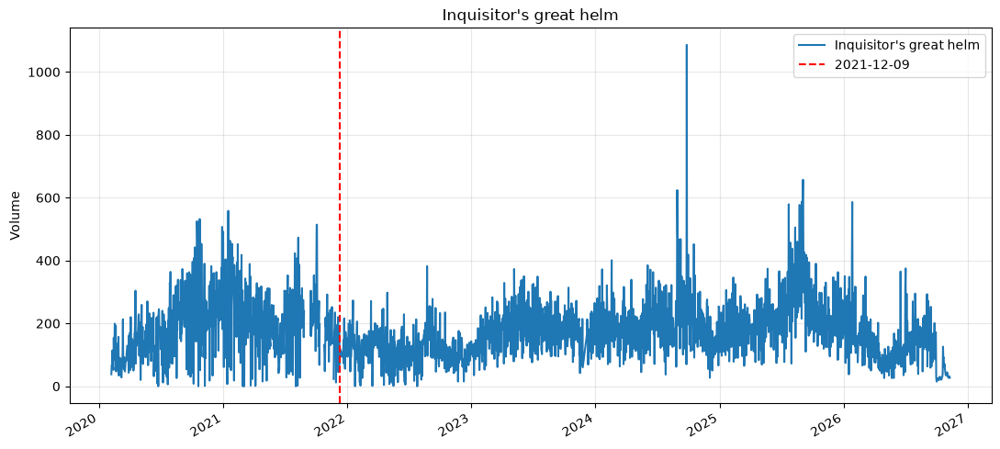

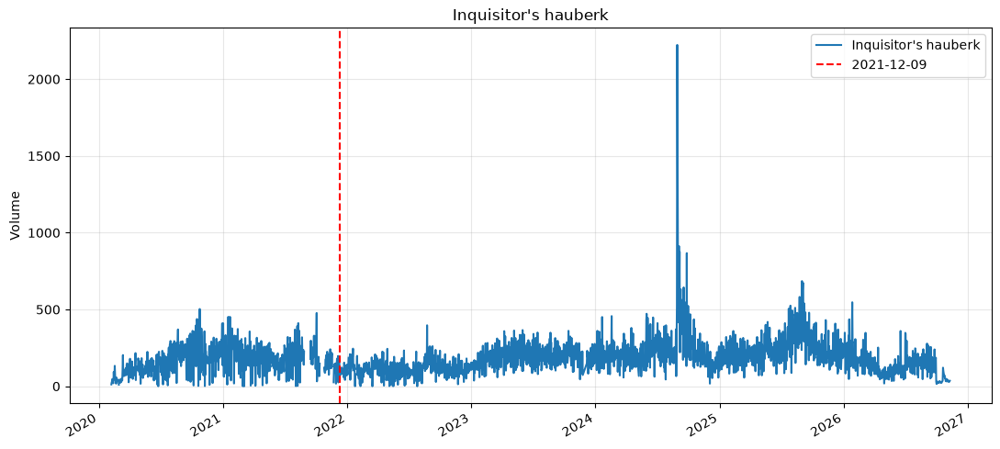

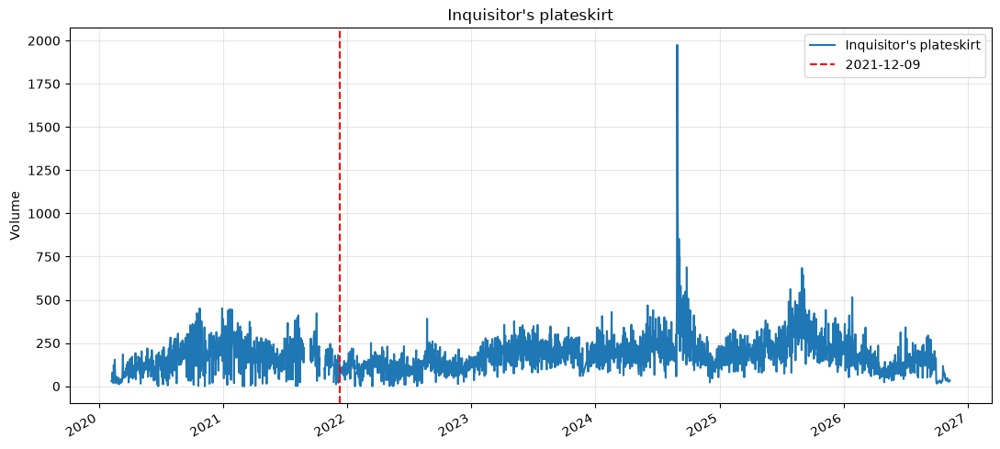

In [229]:
for item in unique_items:
    plot_items_volume(sinkHistDF, item)

In [231]:
def before_after_avg(df, items, split="2021-12-09", col="volume"):
    if isinstance(items, str):
        items = [items]

    split = pd.to_datetime(split)
    sub = df[df["item"].isin(items)].copy()
    sub["period"] = np.where(sub["date"] < split, "before", "after")

    return (
        sub.groupby(["item", "period"])[col]
        .mean()
        .unstack("period")[["before", "after"]]
    )

In [232]:
before_after_avg(sinkHistDF,item)

period,before,after
item,,
Inquisitor's plateskirt,162.678179,163.781676


In [243]:
def plot_before_after(df, items=None, split="2021-12-09", col="volume", log=False, title=None, sort_by="before"):
    avgs = before_after_avg(df, items, split, col)
    if sort_by:
        avgs = avgs.sort_values(sort_by)

    ax = avgs.plot(kind="barh", figsize=(10, max(5, len(avgs) * 0.4)), logx=log, width=0.8,
                   title=title or f"Average {col} before vs after {split}")
    ax.set_xlabel(f"Average {col}")
    ax.set_ylabel("")
    ax.grid(alpha=0.3, axis="x")
    plt.tight_layout()
    plt.show()

    return avgs

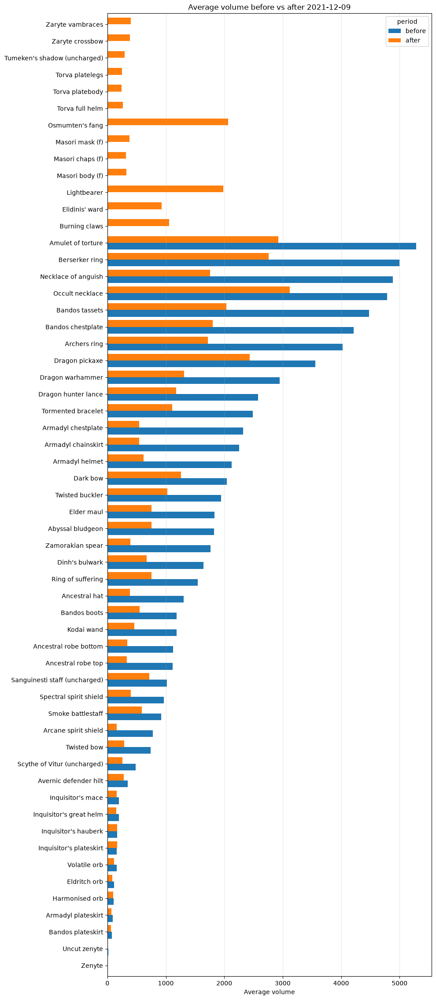

period,before,after
item,,
Zenyte,7.534574,5.000000
Uncut zenyte,14.353497,6.179337
Bandos plateskirt,76.091644,59.232943
Armadyl plateskirt,90.354897,67.327485
Harmonised orb,108.761006,95.795809
Eldritch orb,111.446541,85.300682
Volatile orb,161.689168,115.538986
Inquisitor's plateskirt,162.678179,163.781676
Inquisitor's hauberk,168.852201,168.635478


In [244]:
plot_before_after(sinkHistDF,unique_items)

In [241]:
# filter the history for https://oldschool.runescape.wiki/w/Grand_Exchange?action=history&limit=500&offset= to dec 9 2021